In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import padua
import gseapy
from pycirclize import Circos
import matplotlib.pyplot as plt
import networkx as nx
import requests
import random
import pygraphviz

random.seed(7126)

In [2]:
colors = [
          "#39033bff",
          "#5745F7",
          "#1F7CFE",
          '#d3f0d5',
          '#ffffff'
          ]

custom_colours = sns.blend_palette(colors[::1],
                                   as_cmap=True,
                                   input='rgb',
                                   )

In [3]:
data_raw = pd.read_csv('COVID_KS22027DISites_v2_20250108.txt',
                       sep='\t',
                       low_memory=False,
                       )

In [4]:
intensities = data_raw.filter(regex='Intensity \d{1,2}$',
                              axis=1)

all_sites = pd.DataFrame({'protein' : data_raw['Protein'],
                          'sequence' : data_raw['KS22027DI Probabilities'],
                          'score' : data_raw['Score'],
                          'localization_probability' : data_raw['Localization prob'],
                          'gene' : data_raw['Gene names'],
                          'site' : data_raw['Position'],
                          'sequence_window' : data_raw['Sequence window'],
                          }) \
                          .join(intensities)

In [5]:
# function to filter out sites without at least 3 valid values
def valid_values(data, log_scale=False):

    if log_scale != True: data.replace(0, np.nan, inplace=True)

    is_valid = []

    for sites in pd.Series(data.filter(regex='Intensity \d{1,2}$',
                                       axis=1).values.tolist()):
        valid_sites = [site for site in sites if not pd.isnull(site)]
        if len(valid_sites) >= 3: is_valid.append('y')
        else: is_valid.append('n')

    data['valid_filter'] = is_valid
    
    # filtered dataframe containing only valid sites
    filtered_data = data[(data.valid_filter == 'y')].drop(columns = ['valid_filter'])
    filtered_data = filtered_data[~filtered_data['protein'].str.contains('REV_')]
    return filtered_data

In [6]:
# filter out sites that are not present in at least 3 samples
valid_sites = valid_values(all_sites)

# no need to filter out reverse hits as these are not reproducible across samples
# remove sites with localisation probabilities below eighty percent
valid_sites = valid_sites[(valid_sites.localization_probability >= 0.8)]

# remove duplicates
intensity_columns = valid_sites.filter(regex='Intensity').columns
unique_sites = valid_sites.drop_duplicates(subset=intensity_columns)

In [7]:
# create groups list based on sample IDs
groups = []
for sample in range(0,19):
    groups.append('COVID_')
groups.append('control_')
groups.append('control_')
groups.append('control_')
groups.append('COVID_')
for sample in range(0,10):
    groups.append('control_')
for sample in range(0,6):
    groups.append('COVID_')

In [8]:
# sort data into correct order
column_names = list(unique_sites.filter(regex='Intensity').columns)
new_column_names = []
index = 0

for name in column_names: 
    new_column_names.append(str(groups[index]) + name.lstrip('Intensity '))
    index += 1

column_dict = dict(zip(column_names, new_column_names))
heatmap_data = unique_sites.rename(columns=column_dict)
heatmap_data = heatmap_data[new_column_names]

sites = unique_sites['protein'] + ' - ' + unique_sites['site'].astype(str)

heatmap_data.sort_index(axis=1, inplace=True)

heatmap_mask = heatmap_data.isna()

fc_data = heatmap_data
fc_data['site'] = sites
fc_data = np.log2(fc_data.set_index(['site']))

In [9]:
np.random.seed(7126)

# impute na values from guassian distribution with downshift
imputed = pd.DataFrame(padua.imputation.gaussian(fc_data, width=0.3, downshift=-1.8, prefix=None)[0])

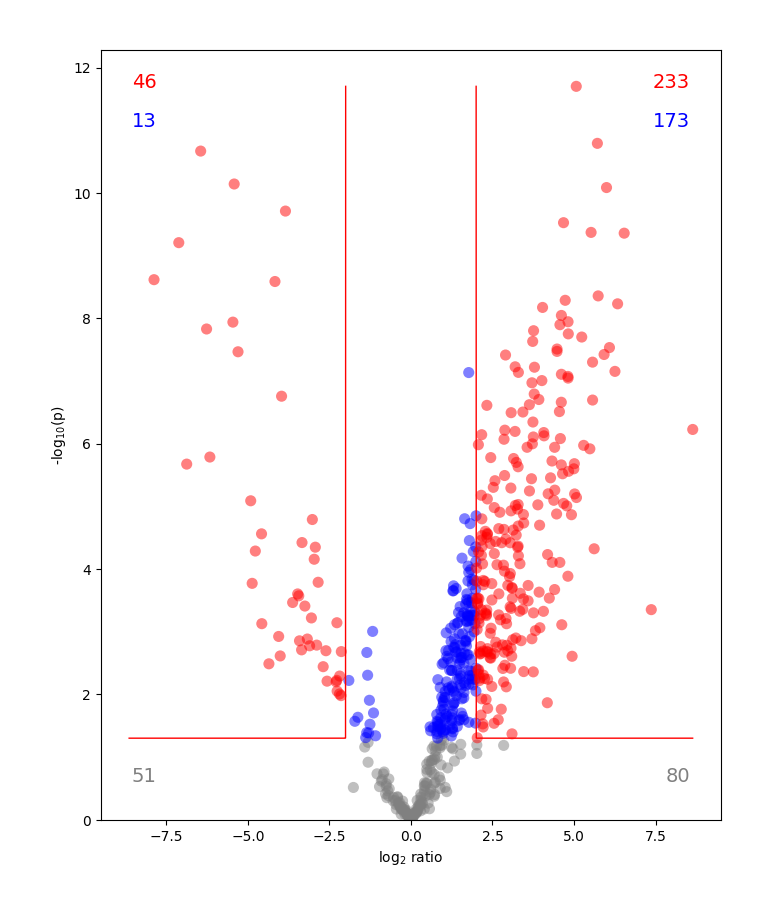

In [10]:
# calculate fold change and stats for volcano and downstream comparisons
# setting threshold of 4 gates significant values with 2 fold increase or decrease
volcano = padua.visualize.volcano(imputed, imputed.filter(regex='control').columns,
                                  b=imputed.filter(regex='COVID').columns, is_log2=True, threshold=4)

# extract values from padua output
p_val = pd.Series(-np.log(volcano[1]))
q_val = pd.Series(padua.utils.qvalues(volcano[1]))
fc_val = pd.Series(volcano[2])
sig_filter = pd.Series(volcano[3])

# filter based on if significant and at least 2 fold change threshold
p_sig = p_val[sig_filter == True]
fc_sig = fc_val[sig_filter == True]

# put everything in one dataframe for later
compare_result = pd.DataFrame({'gene' : unique_sites['gene'].to_numpy(),
                               'neg_log_pval' : p_val,
                               'qval' : q_val,
                               'fc' : fc_val,
                               'sequence_window' : unique_sites['sequence_window'].to_numpy(),
                               'site' : unique_sites['site'].to_numpy()})


In [11]:
# use plotly express for volcano plot to allow interactive annotations
fig = px.scatter(x=fc_val, y=p_val, text=unique_sites['gene'], color=sig_filter)
fig.update_traces(textposition='top center')
fig.add_hline(y=(-np.log(0.05)))
fig.add_vline(x=2)
fig.add_vline(x=-2)

# save figure as vector
# fig.write_image('volcano.svg')

In [12]:
significant_genes = compare_result[compare_result['qval'] < 0.01].sort_values('fc').reset_index().drop(columns='index')
significant_genes = significant_genes[significant_genes['gene'].notnull()]

genes_up = pd.DataFrame()
genes_up = compare_result[compare_result['fc'] >= 2]
genes_up = genes_up[genes_up['qval'] < 0.05]
genes_up['gene'] = pd.Series(str(x).split(';')[0] for x in genes_up['gene']).to_numpy()
genes_up = genes_up[genes_up['gene'] != 'nan'].drop(columns=['qval','neg_log_pval', 'sequence_window', 'site'])

genes_down = pd.DataFrame()
genes_down = compare_result[compare_result['fc'] <= -2]
genes_down = genes_down[genes_down['qval'] < 0.05]
genes_down['gene'] = pd.Series(str(x).split(';')[0] for x in genes_down['gene']).to_numpy()
genes_down = genes_down[genes_down['gene'] != 'nan'].drop(columns=['qval','neg_log_pval', 'sequence_window', 'site'])


In [13]:
# need gmt file format for gsea analysis
# go slim annotation files not available from gsea or as gmt format
# goa file from ebi quick go
go = pd.read_csv("QuickGO-annotations-hsa_slimBP.gaf", sep='\t', comment='!', header=None)

go = go.groupby([4]).agg({1 : list, 2 : list}).reset_index()
go[1] = pd.Series(x[0] for x in go[1])
go[2] = pd.Series('\t'.join([str(y)for y in x]) for x in go[2])

for index, row in go.iterrows():
  with open("QuickGO-annotations-hsa_slimBP.gmt", 'a') as f:
    f.write(str(row[4] + '\t' + row[1] + '\t'  + row[2] + '\n'))


C:\Users\kathe\AppData\Local\Temp\ipykernel_24288\3068394518.py:4: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  go = pd.read_csv("QuickGO-annotations-hsa_slimBP.gaf", sep='\t', comment='!', header=None)


In [14]:
# gsea over representation analysis on only significantly increased genes
gene_list = genes_up['gene']
gene_set = "QuickGO-annotations-hsa_slimBP.gmt"

enr = gseapy.enrichr(gene_list=gene_list,
                 gene_sets=gene_set,
                 organism='human',
                 outdir=None,
                )

# top 10 biological processes in terms of odds ratio
# filtered for categories that contain at least 5 genes
enriched_up = enr.results
enriched_up['number_of_genes'] = list(float(x.split('/')[0]) for x in enriched_up['Overlap'])
top_10 = enriched_up[enriched_up['number_of_genes'] >= 5].sort_values('Odds Ratio', ascending=False)[0:10]
top_10['neg_log_pval'] = pd.Series(-np.log10(x) for x in top_10['Adjusted P-value']).to_numpy()

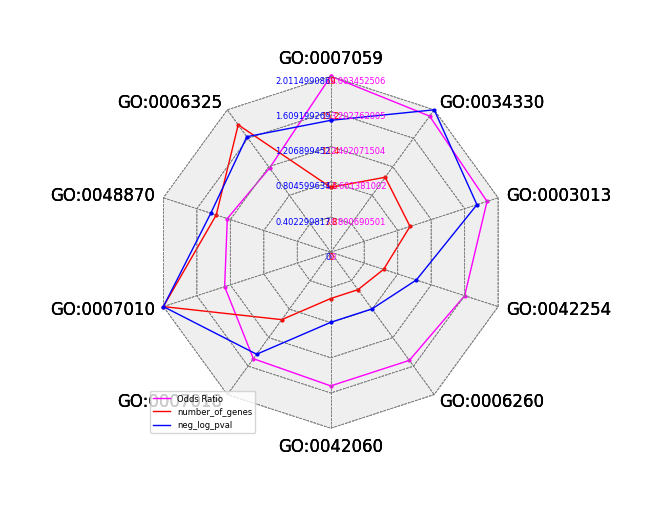

In [15]:
top_10_plot_data = pd.DataFrame(top_10.drop(columns=['Gene_set', 'Overlap', 'P-value', 'Genes', 'Term', 'Adjusted P-value', 'Combined Score'])).T
top_10_plot_data.columns = top_10['Term']

fig, ax = plt.subplots(subplot_kw=dict(polar=True))
index = 0

cmaps = ['spring', 'autumn', 'winter', 'cool']
single_colours = ['fuchsia', 'red', 'blue', 'cyan']
align = ['left', 'center', 'right', 'left', 'center', 'right']

# Plot radar chart into subplots for each target
for target_name in top_10_plot_data.index:
    target_df = top_10_plot_data.loc[[target_name]]


    # Initialize Circos instance for radar chart plot
    circos = Circos.radar_chart(
        target_df,
        vmax=target_df.max(axis=None),
        marker_size=3,
        grid_interval_ratio=0.2,
        fill=False,
        cmap=cmaps[index],
        line_kws_handler=lambda _: dict(ls='solid'),
        grid_label_kws=dict(c=single_colours[index], ha=align[index], size=6),
    )

    # Plot figure & set legend on upper right
    circos.plotfig(ax=ax)
    circos.ax.legend(loc="lower left", fontsize=6)

    index += 1

# # save figure as vector
# fig.savefig('radar.svg')

In [16]:
# gsea on all significant genes ranked by fold change
ranked_gene_list = significant_genes.drop(columns=['neg_log_pval', 'qval', 'fc', 'sequence_window'])

res = gseapy.enrichr(gene_list=ranked_gene_list,
                     gene_sets=['Pfam_Domains_2019'],
                     organism='human',
                     outdir=None,
                     )

enriched_ranked = res.res2d
enriched_ranked['number_of_genes'] = pd.Series(float(x.split('/')[0]) for x in enriched_ranked['Overlap'])

In [17]:
protein_list = genes_up['gene'].tolist()
proteins = '%0d'.join(protein_list)
url = 'https://string-db.org/api/tsv/network?identifiers=' + proteins + '&species=9606'
r = requests.get(url)

lines = r.text.split('\n') # pull the text from the response object and split based on new lines
data = [l.split('\t') for l in lines] # split each line into its components based on tabs
# convert to dataframe using the first row as the column names; drop empty, final row
df = pd.DataFrame(data[1:-1], columns = data[0]) 
# dataframe with the preferred names of the two proteins and the score of the interaction
interactions = df[['preferredName_A', 'preferredName_B', 'score']]
interactions['preferredName_B'] = pd.Series(str(x).replace('KNL1', 'CASC5') for x in interactions['preferredName_B'])
interactions['preferredName_A'] = pd.Series(str(x).replace('MRM3', 'RNMTL1') for x in interactions['preferredName_A'])


C:\Users\kathe\AppData\Local\Temp\ipykernel_24288\2674382117.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  interactions['preferredName_B'] = pd.Series(str(x).replace('KNL1', 'CASC5') for x in interactions['preferredName_B'])
C:\Users\kathe\AppData\Local\Temp\ipykernel_24288\2674382117.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  interactions['preferredName_A'] = pd.Series(str(x).replace('MRM3', 'RNMTL1') for x in interactions['preferredName_A'])


(np.float64(-59.67345),
 np.float64(1148.98345),
 np.float64(-105.73200000000003),
 np.float64(1320.132))

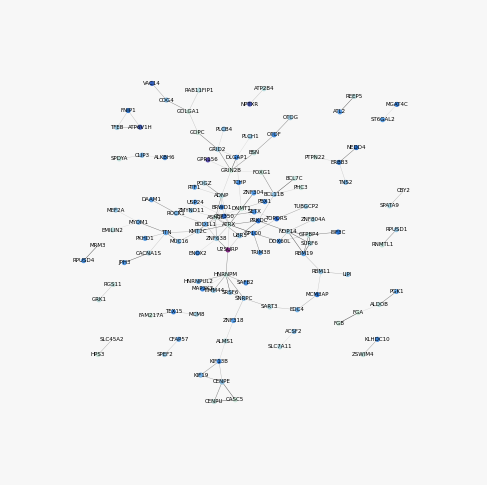

In [18]:
graph_colormap = sns.blend_palette(["#cde8daff",
                                    "#5a9fe4ff",
                                    '#236dcbff',
                                    "#7e2a81e3",
                                    ], as_cmap=True)

ecmap = sns.blend_palette(["#FFFFFFFF",
                           "#959595FF",
                           "#616161FF",
                           "#303030FF",
                           ], as_cmap=True)

G = nx.Graph()
# interactions = pd.DataFrame(interactions).loc[pd.DataFrame(interactions)[0].isin(connected_components.T[0])].sort_values(2, ascending=False)
interactions = np.array(interactions)
for i in range(len(interactions)):
    interaction = interactions[i]
    a = interaction[0] # protein a node
    b = interaction[1] # protein b node
    w = float(interaction[2]) # score as weighted edge where high scores = low weight
    G.add_weighted_edges_from([(a,b,w)]) # add weighted edge to graph

connected_components = pd.DataFrame(nx.connected_components(G))
connected_components['count'] = pd.Series(connected_components.count(axis = 1))

# function to rescale list of values to range [newmin,newmax]
def rescale(l,newmin,newmax):
    arr = list(l)
    return [(x-min(arr))/(max(arr)-min(arr))*(newmax-newmin)+newmin for x in arr]

# node color varies with fold change in expression
nodes_fc = pd.DataFrame()
nodes = list(G.nodes())
# nodes[29] = 'CASC5'
nodes_fc['gene'] = nodes
nodes_fc = nodes_fc.merge(genes_up.groupby('gene').mean(), on='gene', how='left')
c = rescale([x for x in nodes_fc['fc']],0.0,1)
c = [graph_colormap(i) for i in c]

# node size varies with betweeness centrality - map to range [10,100] 
bc = nx.betweenness_centrality(G) # betweeness centrality
s =  rescale([v for v in bc.values()], 10, 100)

# edge width shows 1-weight to convert cost back to strength of interaction 
ew = rescale([float(G[u][v]['weight']) for u,v in G.edges], 0.1, 2)

# edge color also shows weight
ec = rescale([float(G[u][v]['weight']) for u,v in G.edges], 0.1, 1)
ec = [ecmap(i) for i in ec]

T = nx.minimum_spanning_tree(G)

pos = nx.nx_agraph.graphviz_layout(G, prog='neato')

plt.figure(figsize=(5, 5),
           facecolor=[0.7, 0.7, 0.7, 0.1],
           )
nx.draw_networkx(G,
                #  T,
                 pos=pos,
                 with_labels=True,
                 node_color=c,
                 node_size=7,
                 edge_color=ec,
                 width=0.3,
                 font_color='black',
                 font_size='4',
                 )
plt.axis('off')

# plt.savefig('genes_up_network.svg', format='svg')


C:\Users\kathe\AppData\Local\Temp\ipykernel_24288\3938407103.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unique_sites['first_gene'] = list(str(x).split(';')[0] for x in unique_sites['gene'])


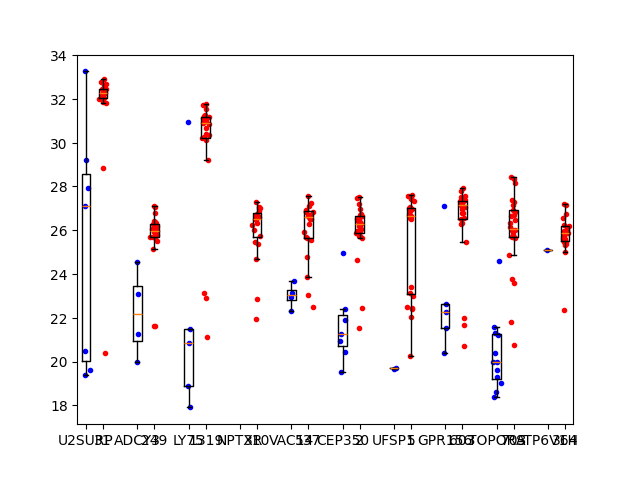

In [19]:
np.random.seed(7126)

unique_sites['first_gene'] = list(str(x).split(';')[0] for x in unique_sites['gene'])
top_10_fc = genes_up.sort_values('fc', ascending=False)[0:10].join(compare_result['site'])
top_10_sites = unique_sites[unique_sites['first_gene'].isin(top_10_fc['gene'].tolist())]
top_10_sites = top_10_sites[top_10_sites['site'].isin(top_10_fc['site'].tolist())]
compare_top10 = pd.DataFrame(np.log2(top_10_sites.filter(regex='Intensity').T))
compare_top10.rename(columns=dict(zip(compare_top10.columns, top_10_sites['first_gene'])), inplace=True)
compare_top10['group'] = [x.strip('_') for x in groups]
compare_top10.set_index('group', inplace=True)

index = 0
for gene in compare_top10:
    y1 = compare_top10[compare_top10.index == 'COVID'][gene]
    y2 = compare_top10[compare_top10.index == 'control'][gene]
    x1 = (np.linspace(index + 1, index + 1, num=len(y1))).tolist()
    x2 = (np.linspace(index, index, num=len(y2))).tolist()
    plt.scatter(x1 + np.random.normal(0, 0.1, size=len(x1)), y1 , c='red', marker='.')
    plt.scatter(x2 + np.random.normal(0, 0.1, size=len(x2)), y2, c='blue', marker='.')
    index += 3

top10_covid = compare_top10[compare_top10.index == 'COVID'].T.to_numpy()
top10_control = compare_top10[compare_top10.index == 'control'].T.to_numpy()
top10_cleaned_covid = [np.array(group)[~np.isnan(group)] for group in top10_covid]
top10_cleaned_control = [np.array(group)[~np.isnan(group)] for group in top10_control]
plt.boxplot(top10_cleaned_control, positions=np.arange(0, len(top10_cleaned_control) * 3, 3), sym='', tick_labels=top_10_sites['gene'], manage_ticks=True)
plt.boxplot(top10_cleaned_covid, positions=np.arange(1, len(top10_cleaned_covid) * 3 + 1, 3), sym='', tick_labels=top_10_sites['site'], manage_ticks=True)

plt.savefig('top10_box.svg')